In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
print("Import Sucess")

Import Sucess


In [3]:
df=pd.read_csv("Healthcare_Patient_Readmission.csv")
print(df.shape)
print(df.columns.tolist())
print(df.info())
print(df.isnull().sum())
print(df.head(5))

(250000, 47)
['Patient_ID', 'Age', 'Gender', 'BMI', 'Blood_Group', 'Smoking_Status', 'Alcohol_Consumption', 'Diagnosis', 'Disease_Category', 'Severity_Level', 'Chronic_Disease_Flag', 'Comorbidity_Count', 'Previous_Admissions', 'Hospital_ID', 'Hospital_Type', 'Department', 'Doctor_ID', 'Bed_Occupancy_Rate', 'Treatment_Type', 'Medication_Count', 'Procedure_Count', 'ICU_Admission', 'Surgery_Flag', 'Heart_Rate', 'Blood_Pressure', 'Oxygen_Saturation', 'Glucose_Level', 'Cholesterol_Level', 'Admission_Date', 'Discharge_Date', 'Length_of_Stay', 'Follow_Up_Days', 'Readmission_Flag', 'Readmission_Days', 'Mortality_Risk_Score', 'Recovery_Score', 'Treatment_Cost_USD', 'Insurance_Coverage', 'Out_of_Pocket_Cost', 'Exercise_Frequency', 'Sleep_Hours', 'Diet_Score', 'Patient_Risk_Score', 'Medication_Adherence', 'Follow_Up_Compliance', 'Hospital_Quality_Score', 'Predicted_Readmission_Risk']
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 47 columns):
 #   Column   

In [4]:
df.head(5)

,Patient_ID,Age,Gender,BMI,Blood_Group,Smoking_Status,Alcohol_Consumption,Diagnosis,Disease_Category,Severity_Level,...,Insurance_Coverage,Out_of_Pocket_Cost,Exercise_Frequency,Sleep_Hours,Diet_Score,Patient_Risk_Score,Medication_Adherence,Follow_Up_Compliance,Hospital_Quality_Score,Predicted_Readmission_Risk
0,PAT0000001,89,Male,26.3,AB-,Former,Low,Asthma,Pulmonology,High,...,37.11,20309.82,0,9.7,8.38,93.75,64.61,46.16,78.70,73.77
1,PAT0000002,60,Female,26.0,B-,Current,Low,Asthma,Cardiology,Critical,...,80.16,9363.01,3,7.9,49.23,22.21,98.68,89.19,29.75,10.61
2,PAT0000003,31,Female,29.4,B+,Never,High,Kidney Disease,Endocrinology,Critical,...,89.61,23306.53,3,7.4,40.84,97.04,76.98,87.50,61.48,78.81
3,PAT0000004,69,Female,19.7,AB+,Never,Low,Hypertension,Cardiology,High,...,93.88,10006.11,5,7.6,95.76,41.04,4.15,97.39,27.10,89.78
4,PAT0000005,72,Female,40.8,A-,Former,NaN,Diabetes,Pulmonology,High,...,20.78,10292.60,4,6.8,85.16,59.74,66.27,69.73,12.25,83.87


In [5]:
df['Alcohol_Consumption'].isna().sum()

np.int64(62732)

In [6]:
df['Alcohol_Consumption'].dtype

<StringDtype(storage='python', na_value=nan)>

In [11]:
df['Alcohol_Consumption'].value_counts(dropna=False)

Alcohol_Consumption
True    250000
Name: count, dtype: int64

In [10]:
df['Alcohol_Consumption'] = df['Alcohol_Consumption'].fillna('No alcohol consumption').inplace=True

In [12]:
df.Alcohol_Consumption

0         True
1         True
2         True
3         True
4         True
          ... 
249995    True
249996    True
249997    True
249998    True
249999    True
Name: Alcohol_Consumption, Length: 250000, dtype: bool

In [13]:
df.describe()

,Age,BMI,Chronic_Disease_Flag,Comorbidity_Count,Previous_Admissions,Bed_Occupancy_Rate,Medication_Count,Procedure_Count,ICU_Admission,Surgery_Flag,...,Insurance_Coverage,Out_of_Pocket_Cost,Exercise_Frequency,Sleep_Hours,Diet_Score,Patient_Risk_Score,Medication_Adherence,Follow_Up_Compliance,Hospital_Quality_Score,Predicted_Readmission_Risk
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,...,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.00000,250000.000000,250000.000000,250000.000000
mean,56.026628,30.502071,0.499904,3.505252,9.522424,75.001425,6.993160,4.498540,0.201152,0.299264,...,49.963748,24932.879582,2.990684,6.501814,49.922419,49.990513,50.06949,50.019279,49.970630,50.033692
std,22.200367,8.372445,0.500001,2.288846,5.763629,14.459801,4.325588,2.870714,0.400862,0.457937,...,28.865372,14449.954945,1.999557,2.019032,28.864359,28.843009,28.86395,28.872672,28.865385,28.859981
min,18.000000,16.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.120000,0.000000,3.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,37.000000,23.300000,0.000000,2.000000,5.000000,62.480000,3.000000,2.000000,0.000000,0.000000,...,24.980000,12396.570000,1.000000,4.700000,24.950000,25.000000,25.08000,24.980000,24.990000,25.010000
50%,56.000000,30.500000,0.000000,4.000000,10.000000,75.000000,7.000000,4.000000,0.000000,0.000000,...,50.030000,24878.945000,3.000000,6.500000,49.855000,49.970000,50.05000,50.120000,49.990000,50.060000
75%,75.000000,37.800000,1.000000,6.000000,15.000000,87.540000,11.000000,7.000000,0.000000,1.000000,...,74.900000,37454.845000,5.000000,8.300000,74.980000,74.922500,75.06000,75.030000,75.010000,75.020000
max,94.000000,45.000000,1.000000,7.000000,19.000000,100.000000,14.000000,9.000000,1.000000,1.000000,...,100.000000,49999.910000,6.000000,10.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000


In [15]:
df['Gender'].value_counts()

Gender
Female    125042
Male      124958
Name: count, dtype: int64

In [16]:
df['Disease_Category'].value_counts()

Disease_Category
Cardiology       63078
Pulmonology      62670
Nephrology       62141
Endocrinology    62111
Name: count, dtype: int64

In [17]:
df['Blood_Group'].value_counts()

Blood_Group
A-     31486
AB+    31448
AB-    31293
A+     31238
O+     31196
B-     31185
B+     31138
O-     31016
Name: count, dtype: int64

In [18]:
df['Smoking_Status'].value_counts(),
df['Severity_Level'].value_counts()

Severity_Level
Low         63147
High        62377
Medium      62266
Critical    62210
Name: count, dtype: int64

In [21]:
df.groupby('Disease_Category')['Age'].mean().sort_values(ascending=False)

Disease_Category
Nephrology       56.172495
Endocrinology    56.053453
Cardiology       55.945956
Pulmonology      55.936604
Name: Age, dtype: float64

In [22]:
df.groupby('Severity_Level')['BMI'].mean()

Severity_Level
Critical    30.486509
High        30.533756
Low         30.506417
Medium      30.481471
Name: BMI, dtype: float64

In [23]:
df.groupby('Disease_Category')['Previous_Admissions'].mean().sort_values(ascending=False)

Disease_Category
Pulmonology      9.555513
Endocrinology    9.524191
Cardiology       9.508418
Nephrology       9.501505
Name: Previous_Admissions, dtype: float64

In [24]:
df.groupby('Chronic_Disease_Flag').agg(
    Avg_Age=('Age', 'mean'),
    Avg_BMI=('BMI', 'mean'),
    Avg_Admissions=('Previous_Admissions', 'mean'),
    Avg_Comorbidities=('Comorbidity_Count', 'mean')
)

,Avg_Age,Avg_BMI,Avg_Admissions,Avg_Comorbidities
Chronic_Disease_Flag,,,,
0,56.021372,30.482003,9.522700,3.511030
1,56.031886,30.522147,9.522148,3.499472


In [25]:
df.groupby('Department').agg(
    Patients=('Patient_ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_BMI=('BMI', 'mean'),
    Avg_Admissions=('Previous_Admissions', 'mean'),
    Avg_Comorbidities=('Comorbidity_Count', 'mean')
).sort_values('Patients', ascending=False)

,Patients,Avg_Age,Avg_BMI,Avg_Admissions,Avg_Comorbidities
Department,,,,,
Emergency,50274,55.968035,30.533471,9.503640,3.516669
Cardiology,50181,56.039876,30.422413,9.521472,3.504494
General,50003,56.023839,30.501176,9.540528,3.500390
ICU,49821,56.149355,30.535184,9.497541,3.506855
Neurology,49721,55.952334,30.518439,9.549104,3.497757


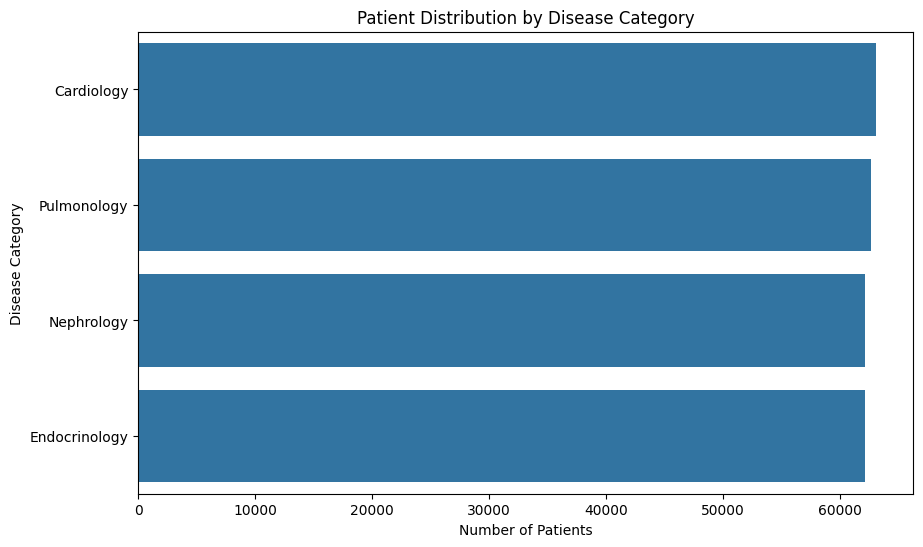

In [33]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y='Disease_Category',
    order=df['Disease_Category'].value_counts().index
)

plt.title('Patient Distribution by Disease Category')
plt.xlabel('Number of Patients')
plt.ylabel('Disease Category')
plt.show()

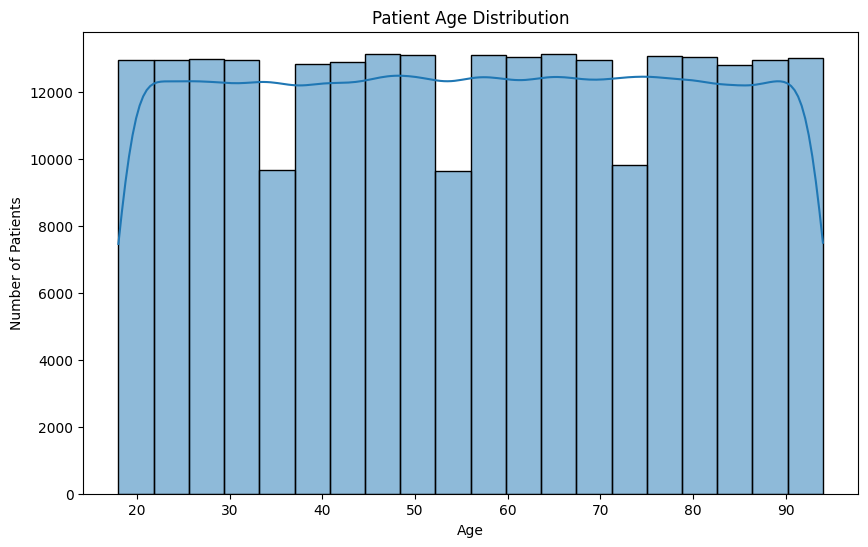

In [34]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Age',
    bins=20,
    kde=True
)

plt.title('Patient Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.show()

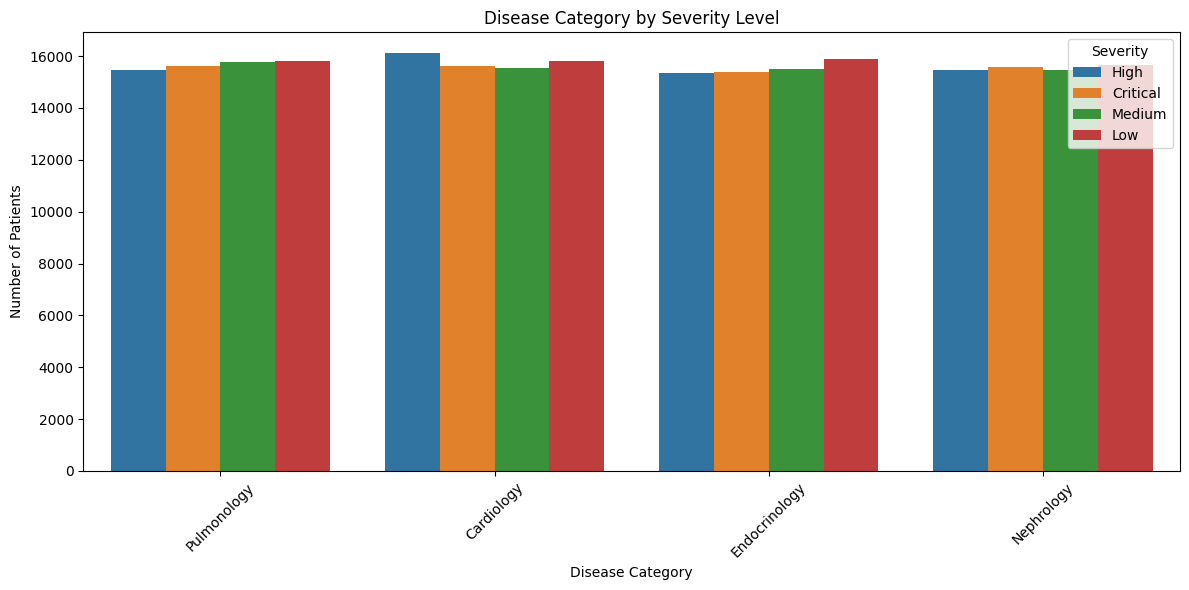

In [35]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='Disease_Category',
    hue='Severity_Level'
)

plt.title('Disease Category by Severity Level')
plt.xlabel('Disease Category')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.legend(title='Severity')
plt.tight_layout()
plt.show()

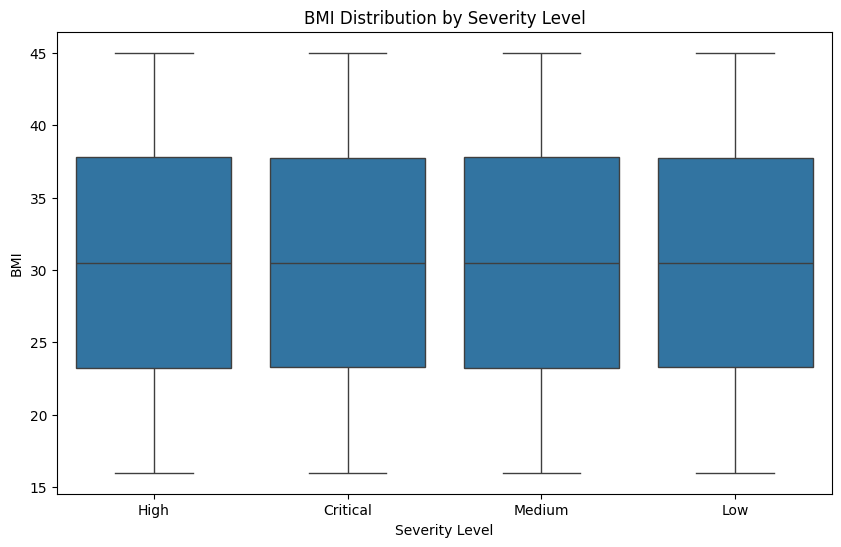

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Severity_Level',
    y='BMI'
)

plt.title('BMI Distribution by Severity Level')
plt.xlabel('Severity Level')
plt.ylabel('BMI')
plt.show()

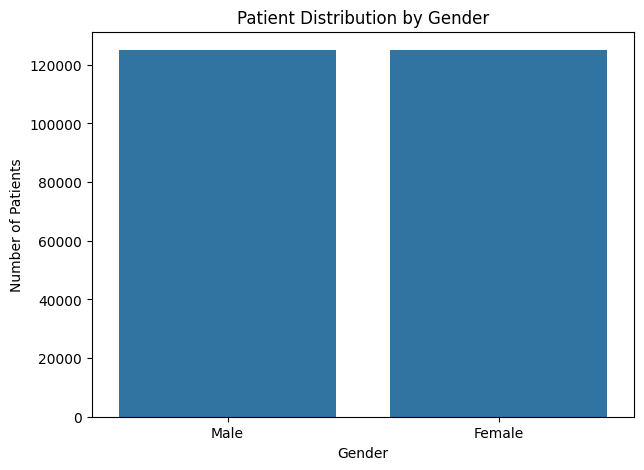

In [38]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Gender'
)

plt.title('Patient Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Patients')
plt.show()